# 02. Results of the national application, 2014-2024

All tables and figures here are read from the aggregate files in `results/real/`. No record-level data are included.

Unit of analysis: the 260,219 neonatal death records of the SIM files of 2014-2024, each identified by file year and row.
**Linkage yield** is the proportion of death records assigned an accepted birth record after consolidation. It does not
measure the correctness of accepted pairs or the completeness of vital registration.

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
R = "results/real/"
flow = json.load(open(R + "flow_counts.json"))
c3 = flow["configs"]["C03"]
print({k: c3[k] for k in ("L", "U", "pct", "by_stage")}, "N =", flow["N_deaths"])

{'L': 231478, 'U': 28741, 'pct': 88.95507245819867, 'by_stage': {'P3': 2957, 'CLF': 16374, 'P2': 20860, 'P1': 191287}} N = 260219


## Record flow and reconciliation of counting rules

In [2]:
leg = flow["legacy"]
print("accepted proposals summed over annual runs:", leg["matched"])
print("same pair repeated across runs:", flow["overlap_C03"]["same_birth"])
print("distinct pairs:", leg["matched"] - flow["overlap_C03"]["same_birth"])
print("deaths with a proposal:", c3["deaths_proposed"], "| proposals rejected in consolidation:", c3["dropped_birth_already_taken"])
print("linked after consolidation:", c3["L"])
print("alternative priority rule changed status for", flow["conflict_policy_audit_C03"]["status_changes"], "deaths")
pd.read_csv(R + "legacy_reconciliation.csv")

accepted proposals summed over annual runs: 234118
same pair repeated across runs: 2635
distinct pairs: 231483
deaths with a proposal: 231480 | proposals rejected in consolidation: 5
linked after consolidation: 231478
alternative priority rule changed status for 0 deaths


,year,run_deaths,file_deaths,matched_C03,legacy_matched,ok,candidate_pairs
0,2014,26791,26509,22957,22957,True,45245
1,2015,26649,26334,23295,23295,True,51447
2,2016,25251,24973,22290,22290,True,45126
3,2017,25782,25463,22883,22883,True,45994
4,2018,25328,25004,22634,22634,True,45483
5,2019,24630,24317,22121,22121,True,42510
6,2020,22721,22405,20273,20273,True,31363
7,2021,22616,22326,20200,20200,True,35820
8,2022,21875,21576,19760,19760,True,32173
9,2023,21723,21461,19698,19698,True,33338


## Yield by year of SIM file

In [3]:
sens = pd.read_csv(R + "sensitivity_strata.csv")
yr = sens[(sens.config == "C03") & (sens.variable == "year")].copy()
yr["yield_%"] = (100 * yr.L_g / yr.N_g).round(1)
yr[["category", "N_g", "L_g", "U_g", "yield_%"]].rename(columns={"category": "SIM file year", "N_g": "deaths", "L_g": "linked", "U_g": "unlinked"})

,SIM file year,deaths,linked,unlinked,yield_%
67,2014,26509,22712,3797,85.7
68,2015,26334,23024,3310,87.4
69,2016,24973,22048,2925,88.3
70,2017,25463,22603,2860,88.8
71,2018,25004,22347,2657,89.4
72,2019,24317,21846,2471,89.8
73,2020,22405,20004,2401,89.3
74,2021,22326,19936,2390,89.3
75,2022,21576,19486,2090,90.3
76,2023,21461,19465,1996,90.7


## Composition of linked and unlinked deaths (reference configuration)

In [4]:
comp = pd.read_csv(R + "composition_C03.csv")
comp = comp[comp.variable != "year"].copy()
comp["unlinked_within_category_%"] = comp.pct_unlinked_in_stratum.round(1)
comp[["variable", "category", "N_g", "L_g", "U_g", "unlinked_within_category_%", "pct_of_all_unlinked"]].round(1)

,variable,category,N_g,L_g,U_g,unlinked_within_category_%,pct_of_all_unlinked
0,weight,invalid,500,359,141,28.2,0.5
1,weight,missing,15264,3713,11551,75.7,40.2
2,weight,valid,244455,227406,17049,7.0,59.3
3,region_of_occurrence,Center-West,21614,19061,2553,11.8,8.9
4,region_of_occurrence,North,33238,29045,4193,12.6,14.6
5,region_of_occurrence,Northeast,82617,72323,10294,12.5,35.8
6,region_of_occurrence,South,29763,27677,2086,7.0,7.3
7,region_of_occurrence,Southeast,92987,83372,9615,10.3,33.5
8,place_of_death,Home,4043,2574,1469,36.3,5.1
9,place_of_death,Hospital,250681,224932,25749,10.3,89.6


## Sensitivity to four predefined configurations

Configurations: exact passes only (E); full procedure at τ = 0.2, 0.3 (reference), and 0.6. Inputs, candidates, model and
consolidation rule are unchanged. The monotone response of yield to τ and the absence of changed births follow from the
construction, because assignment is decided before the threshold.

In [5]:
ov = pd.read_csv(R + "sensitivity_overall.csv"); tr = pd.read_csv(R + "sensitivity_transitions.csv")
ov.merge(tr[["config", "gains", "losses", "different_birth"]], on="config").round(2)

,config,N,L,U,pct_linked,diff_pp_vs_C03,P1,P2,P3,CLF,gains,losses,different_birth
0,E,260219,215104,45115,82.66,-6.29,191287,20860,2957,0,0,16374,0
1,C02,260219,234537,25682,90.13,1.18,191287,20860,2957,19433,3059,0,0
2,C03,260219,231478,28741,88.96,0.00,191287,20860,2957,16374,0,0,0
3,C06,260219,228312,31907,87.74,-1.22,191287,20860,2957,13208,0,3166,0


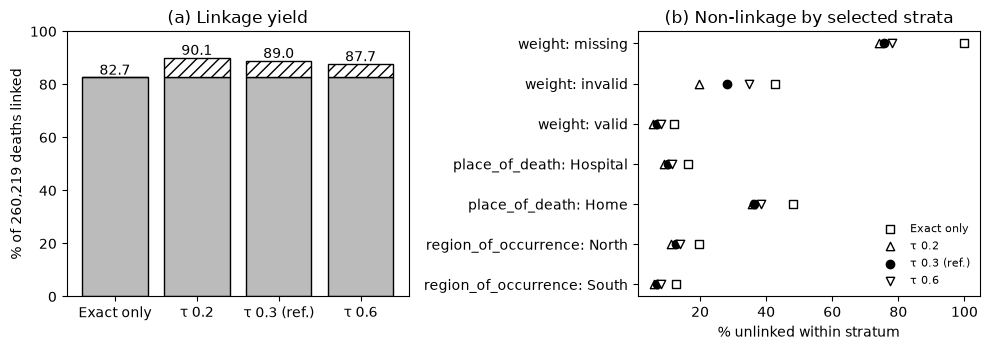

In [6]:
cfgs = ["E", "C02", "C03", "C06"]; lab = ["Exact only", "τ 0.2", "τ 0.3 (ref.)", "τ 0.6"]
o = ov.set_index("config")
exact = [(o.loc[c, "P1"] + o.loc[c, "P2"] + o.loc[c, "P3"]) / o.loc[c, "N"] * 100 for c in cfgs]
clf = [o.loc[c, "CLF"] / o.loc[c, "N"] * 100 for c in cfgs]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].bar(lab, exact, color="#bbbbbb", edgecolor="k"); ax[0].bar(lab, clf, bottom=exact, color="white", edgecolor="k", hatch="///")
for i, c in enumerate(cfgs): ax[0].text(i, exact[i] + clf[i] + 1, f"{o.loc[c, 'pct_linked']:.1f}", ha="center")
ax[0].set_ylim(0, 100); ax[0].set_ylabel("% of 260,219 deaths linked"); ax[0].set_title("(a) Linkage yield")
sel = [("weight", "missing"), ("weight", "invalid"), ("weight", "valid"), ("place_of_death", "Hospital"), ("place_of_death", "Home"), ("region_of_occurrence", "North"), ("region_of_occurrence", "South")]
for k, (v, cat) in enumerate(sel):
    for c, m in zip(cfgs, "s^ov"):
        r = sens[(sens.config == c) & (sens.variable == v) & (sens.category == cat)].iloc[0]
        ax[1].scatter(r.pct_unlinked_in_stratum, k, marker=m, facecolor="k" if c == "C03" else "white", edgecolor="k", label=lab[cfgs.index(c)] if k == 0 else None)
ax[1].set_yticks(range(len(sel))); ax[1].set_yticklabels([f"{v}: {c}" for v, c in sel]); ax[1].invert_yaxis()
ax[1].set_xlabel("% unlinked within stratum"); ax[1].legend(frameon=False, fontsize=8); ax[1].set_title("(b) Non-linkage by selected strata")
plt.tight_layout(); plt.show()

### Who is recovered by the classifier stage?

The decisions change not only how many deaths are left out but who is left out. Exact passes require weight, so none of the
deaths with missing weight can link by exact passes.

In [7]:
rec = pd.read_csv(R + "classifier_recovery_by_weight.csv"); display(rec.round(1))
ch = pd.read_csv(R + "sensitivity_changes_by_weight.csv"); display(ch[ch.n_total > 0])
share = sens[(sens.variable == "weight") & (sens.category == "missing")][["config", "pct_unlinked_in_stratum", "pct_of_all_unlinked"]].round(1)
share.rename(columns={"pct_unlinked_in_stratum": "% unlinked among missing weight", "pct_of_all_unlinked": "% of all unlinked that have missing weight"})

,weight_status,unlinked_exact_only,linked_by_classifier_C03,pct_recovered
0,missing,15264,3713,24.3
1,invalid,214,73,34.1
2,valid,29637,12588,42.5


,config,change,weight_status,n,n_total
3,E,loss_vs_C03,missing,3713,16374
4,E,loss_vs_C03,invalid,73,16374
5,E,loss_vs_C03,valid,12588,16374
6,C02,gain_vs_C03,missing,250,3059
7,C02,gain_vs_C03,invalid,42,3059
8,C02,gain_vs_C03,valid,2767,3059
21,C06,loss_vs_C03,missing,372,3166
22,C06,loss_vs_C03,invalid,33,3166
23,C06,loss_vs_C03,valid,2761,3166


,config,% unlinked among missing weight,% of all unlinked that have missing weight
1,E,100.0,33.8
27,C02,74.0,44.0
53,C03,75.7,40.2
79,C06,78.1,37.4


## Association with non-linkage (logistic model, reference configuration)

In [8]:
md = pd.read_csv(R + "nonlinkage_model_C03.csv"); meta = json.load(open(R + "nonlinkage_model_metadata.json"))
print({k: meta[k] for k in ("n", "events", "converged", "references")})
md[md.term != "const"].round(3)

{'n': 260219, 'events': 28741, 'converged': True, 'references': {'region': 'Center-West', 'weight': '1000-1499', 'race': 'race_1', 'place': 'Hospital'}}


,term,n_in_category,n_unlinked_in_category,OR,lo95,hi95,p_value
1,region=North,33238.0,4193.0,0.911,0.857,0.969,0.003
2,region=Northeast,82617.0,10294.0,0.974,0.923,1.028,0.337
3,region=South,29763.0,2086.0,0.653,0.609,0.701,0.000
4,region=Southeast,92987.0,9615.0,0.695,0.659,0.734,0.000
5,weight=1500-2499,46672.0,3737.0,1.197,1.134,1.263,0.000
6,weight=<1000,100574.0,5057.0,0.765,0.727,0.804,0.000
7,weight=>=2500,61690.0,5889.0,1.394,1.326,1.465,0.000
8,weight=invalid,500.0,141.0,5.161,4.223,6.309,0.000
9,weight=missing,15264.0,11551.0,41.690,39.396,44.118,0.000
10,race=race_2,6356.0,571.0,0.979,0.884,1.085,0.691


## Agreement on fields not used in linkage (descriptive, not an accuracy estimate)

In [9]:
pd.read_csv(R + "concordance_C03.csv").round(3)

,stage,field,n_pairs,n_compared,pct_comparable,agreement,random_pairing_comparator
0,exact,CODMUNRES,215104,215104,100.000,0.956,0.005
1,exact,SEMAGESTAC,215104,194537,90.439,0.649,0.050
2,exact,ESCMAE,215104,189118,87.919,0.827,0.421
3,exact,GRAVIDEZ,215104,213183,99.107,0.990,0.800
4,exact,PARTO,215104,212315,98.703,0.976,0.500
5,classifier,CODMUNRES,16374,16374,100.000,0.895,0.004
6,classifier,SEMAGESTAC,16374,13361,81.599,0.523,0.052
7,classifier,ESCMAE,16374,14167,86.521,0.751,0.405
8,classifier,GRAVIDEZ,16374,15716,95.981,0.979,0.823
9,classifier,PARTO,16374,15546,94.943,0.928,0.503


The agreement is descriptive. The compared fields are associated with the linkage keys, fill quality differs between the
stages, and false pairs inside candidate blocks may agree more often than random pairs.